In [14]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph,START,END

In [15]:
if os.environ.get("OPENAI_API_KEY"):
    API_KEY = os.environ.get("OPENAI_API_KEY")
    print("api key is set!")
else:
    raise ValueError("API Key is not preset!!")

api key is set!


In [16]:
llm = init_chat_model("gpt-5-nano",temperature = 0)
llm.invoke("waht is ai?")

AIMessage(content='AI stands for artificial intelligence. It’s the field of computer science focused on making machines that can do things that usually require human intelligence. That includes understanding language, recognizing images or sounds, learning from data, solving problems, and making decisions.\n\nKey points:\n- Types: \n  - Narrow (or weak) AI: specialized for one task (e.g., voice assistants, spam filters, image recognition).\n  - General (or strong) AI: hypothetical systems that can do anything a human can do (not yet achieved).\n- How it works (at a high level): most AI today uses machine learning, where computers learn patterns from lots of data. Deep learning, a subset of ML, uses large neural networks to handle complex tasks like language and vision.\n- Examples: voice assistants (like me), photo tagging, fraud detection, movie/music recommendations, self-driving cars.\n- Important caveats: AI isn’t conscious or truly understanding things; it can reflect biases in da

In [17]:
from pydantic import BaseModel,Field

class  graph_schema(BaseModel):
    topic:str = Field(description="The topic of the graph")
    post:str = Field(description="The Linkedin post Content")
    curated_post:str = Field(description="The cureated Linkedin post content")

demo_proj = graph_schema(
    topic = "Tell me importance of AI",
    post = "AI is king!",
    curated_post= "Ai is eveything"
)


In [28]:
def create_post(state:graph_schema)-> graph_schema:
    state = state.model_dump()
    topic = state['topic']
    post = llm.invoke(f"Write me a linkdein post about {topic}").content
    state['post'] = post
    return state

def curated_post(state:graph_schema)-> graph_schema:
    state = state.model_dump()
    topic = state['topic']
    curated_post = llm.invoke(f"Curate the following post:{topic}").content
    state['curated_post']  = curated_post
    return state


In [29]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)

graph.add_node("curated_post",curated_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post","curated_post")
graph.add_edge("curated_post",END)

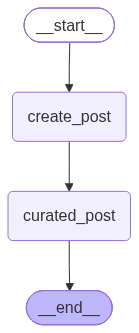

In [30]:
from IPython.display import Image,display

pydantic_graph = graph.compile()

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [31]:
pydantic_graph.invoke({"topic":"Tell me importance of AI",
                       "post":" ",
                       "curated_post":" "})

{'topic': 'Tell me importance of AI',
 'post': 'AI isn’t just a buzzword—it’s a force multiplier for growth, resilience, and innovation. Here’s why it matters across every function:\n\n- Efficiency and productivity: automates repetitive tasks, accelerates workflows, and reduces human error so teams can focus on high-value work.\n- Better decision-making: unlocks data-driven insights, anomaly detection, and predictive analytics to guide strategy and forecasting.\n- Personalization at scale: delivers tailored experiences for customers, partners, and employees, enhancing engagement and outcomes.\n- Innovation and new business models: enables smarter products, dynamic pricing, and services that adapt in real time.\n- Workforce transformation: augments human capabilities, creates opportunities for upskilling, and frees time for strategic thinking.\n- Risk management and governance: supports ethics, transparency, security, and compliance through monitoring and governance tools.\n\nExample fr